# Logo system

*A triangle, a circle, and the golden ratio hiding where they meet.*

This notebook is the source of the visual identity of yairmau.com and its sister sites. It is a design document and a drawing machine at once: every mark is generated from the same few lines of geometry, so the whole system stays coherent by construction. Change a number here and every logo, favicon and export follows.

The idea comes from a classic piece of geometry, the [golden ratio construction on cut-the-knot](https://www.cut-the-knot.org/do_you_know/GoldenRatioPoster.shtml): a right triangle with legs 1 and 2, and a circle of diameter 1 resting on its long side. The proportions of the mark come from that construction. The only real choices are how heavy to draw it.

- Ingredients
- The geometry
- The mark
- Two readings: Earth and Galileo
- The φ mark
- Colour
- Stress test
- Rules of use
- Export

## Ingredients

Two numbers in this cell are design decisions: the weight of the ring in the primary mark, and the weight of the φ mark. Everything else is dictated by the geometry. Lengths are in the units of the construction, where the triangle's short leg is 1.

In [1]:
from pathlib import Path as FilePath

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Polygon, Circle
from matplotlib.transforms import Affine2D
from PIL import Image

PHI = (1 + np.sqrt(5)) / 2

# The construction: right triangle (0,0), (1,0), (0,2) and a circle of diameter 1
# centered on the midpoint of the hypotenuse.
TRIANGLE = np.array([(0, 0), (1, 0), (0, 2)], dtype=float)
CENTER = np.array([0.5, 1.0])
R = 0.5
U = np.array([-1.0, 2.0]) / np.sqrt(5)  # unit vector along the hypotenuse, toward the top tip
N = np.array([U[1], -U[0]])              # unit vector perpendicular to it, pointing away from the triangle

# Stroke weights
WIDTH = 0.05     # primary mark: ring thickness, and the thinnest wall anywhere in the shape
PHI_RING = 0.18  # φ mark: ring and pole thickness, heavier because it is used at small sizes

# Colours: the Midnight palette of yairmau.com
NAVY = "#0d1f2d"       # navbar and buttons, and the logo's default colour
INK = "#1e2a33"        # body text
LINK_BLUE = "#0071eb"  # links only, never the logo
WHITE = "#ffffff"
DARK_TAB = "#292a2d"   # a typical dark browser tab, used for previews

EXPORT = True              # set to False to explore without writing files
OUT = FilePath("logo")     # exported files go here, next to this notebook

## The geometry

Draw a right triangle with legs 1 and 2. Its long side, the hypotenuse, is $\sqrt{1^2+2^2}=\sqrt{5}$.

Now set a circle of diameter 1 on the midpoint of that hypotenuse. It covers exactly the middle unit and leaves two equal ends:

$$\frac{\sqrt{5}-1}{2} = \frac{1}{\varphi} \approx 0.618$$

Walk down the hypotenuse from the top tip. After $1/\varphi$ you enter the circle. After $1/\varphi + 1 = \varphi \approx 1.618$ you leave it. The golden ratio, built from nothing but 1 and 2.

Two consequences shape everything that follows:

- **The circle touches the long leg at a single point.** Its center sits 0.5 from that leg, exactly its radius. This is the most delicate spot in the design, and *The mark* below deals with it.
- **The hypotenuse leans 26.6° away from vertical** ($\arctan\tfrac12$). *Two readings* below explains why that number matters.

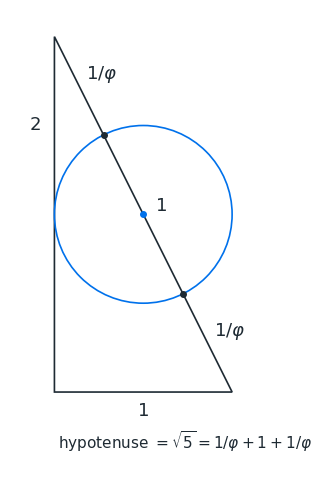

tip to circle: 0.6180   1/phi = 0.6180
tip to far side of circle: 1.6180   phi = 1.6180


In [2]:
upper, lower = CENTER + R * U, CENTER - R * U   # where the hypotenuse crosses the circle

fig, ax = plt.subplots(figsize=(4.5, 6))
ax.add_patch(Polygon(TRIANGLE, closed=True, fill=False, ec=INK, lw=1.2))
ax.add_patch(Circle(CENTER, R, fill=False, ec=LINK_BLUE, lw=1.2))
ax.plot(*np.array([upper, lower]).T, "o", color=INK, ms=4)
ax.plot(*CENTER, "o", color=LINK_BLUE, ms=4)

def label(point, text, offset):
    ax.annotate(text, point, xytext=offset, textcoords="offset points",
                ha="center", va="center", fontsize=13, color=INK)

label((0.5, 0), "$1$", (0, -14))
label((0, 1.5), "$2$", (-14, 0))
label((TRIANGLE[2] + upper) / 2, r"$1/\varphi$", tuple(18 * N))
label(CENTER, r"$1$", tuple(14 * N))
label((lower + TRIANGLE[1]) / 2, r"$1/\varphi$", tuple(18 * N))
ax.text(0.02, -0.32, r"hypotenuse $=\sqrt{5}=1/\varphi + 1 + 1/\varphi$", fontsize=11, color=INK)

ax.set_aspect("equal")
ax.set_xlim(-0.25, 1.35)
ax.set_ylim(-0.45, 2.15)
ax.axis("off")
plt.show()

print(f"tip to circle: {np.linalg.norm(TRIANGLE[2] - upper):.4f}   1/phi = {1 / PHI:.4f}")
print(f"tip to far side of circle: {np.linalg.norm(TRIANGLE[2] - lower):.4f}   phi = {PHI:.4f}")

## The mark

Cut the circle out of the triangle. What remains is a solid wedge holding a void. The half of the circle that falls outside the triangle is kept as a fine ring, so the eye still completes the whole circle. It is the tension between the heavy wedge and the hairline ring that gives the mark its character.

Two refinements make it hold together:

- **The golden ratio lives on the silhouette.** The circle of diameter 1 is the ring's outer edge, and the ring grows inward from it. Where the hypotenuse meets that edge, it is exactly $1/\varphi$ from the tip.
- **There are no hairlines and no spikes.** Left alone, the circle would touch the long leg at a point, and the wedge would taper into two needle-thin horns. Making the void slightly smaller than the circle (radius $0.5 -$ `WIDTH`) leaves a wall at that spot as thick as the ring itself. One weight governs the whole mark: nothing is thinner than the ring.

The mark is drawn as a single shape, so exported files are clean.

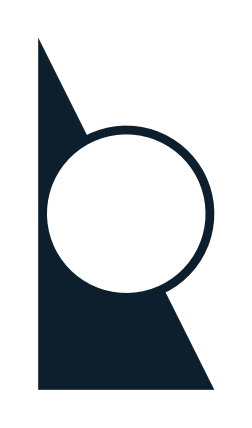

In [3]:
def arc(center, radius, theta1, theta2):
    """Vertices of a counterclockwise circular arc (cubic Bezier segments), from theta1 to theta2 in degrees."""
    return center + radius * Path.arc(theta1, theta2).vertices


def primary_mark(width=WIDTH):
    """The primary mark, upright, inside the box 0 <= x <= 1, 0 <= y <= 2."""
    hole = R - width
    a_up = np.degrees(np.arctan2(U[1], U[0]))  # direction from the center to the upper crossing

    # Solid: the triangle with a half-disc notch of radius `hole` on its inner side.
    notch = arc(CENTER, hole, a_up, a_up + 180)[::-1]  # walked from the lower crossing up to the upper one
    solid = Path([TRIANGLE[0], TRIANGLE[1], *notch, TRIANGLE[2], TRIANGLE[0]],
                 [Path.MOVETO, Path.LINETO, Path.LINETO] + [Path.CURVE4] * (len(notch) - 1)
                 + [Path.LINETO, Path.CLOSEPOLY])

    # Ring: the outer half of the circle, between radius `hole` and R. Its ends lie on the hypotenuse.
    outer = arc(CENTER, R, a_up + 180, a_up + 360)
    inner = arc(CENTER, hole, a_up + 180, a_up + 360)[::-1]
    ring = Path([*outer, *inner, outer[0]],
                [Path.MOVETO] + [Path.CURVE4] * (len(outer) - 1)
                + [Path.LINETO] + [Path.CURVE4] * (len(inner) - 1) + [Path.CLOSEPOLY])

    return Path.make_compound_path(solid, ring)


def draw(ax, path, color=NAVY, background=None, pad=0.08):
    """Draw a mark on an axis, framed tightly with a small margin."""
    ax.add_patch(PathPatch(path, facecolor=color, edgecolor="none"))
    box = path.get_extents()
    m = pad * max(box.width, box.height)
    ax.set_xlim(box.x0 - m, box.x1 + m)
    ax.set_ylim(box.y0 - m, box.y1 + m)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    if background:
        ax.set_facecolor(background)


mark = primary_mark()
fig, ax = plt.subplots(figsize=(3, 6))
draw(ax, mark)
plt.show()

## Two readings: Earth and Galileo

Stand the mark up and it is a planet. Lay it down and it is an experiment. It is the same shape and the same geometry, telling two stories that together describe a path from physics to the environment.

### Vertical: Earth

Upright, the hypotenuse becomes an axis through a sphere. Because the triangle's legs are 1 and 2, that axis leans 26.6° from vertical, about three degrees off the 23.4° tilt of Earth's own axis, the tilt that gives us seasons. The mark gets there by pure geometry, without bending the golden ratio.

Read this way, the solid wedge is ground and the fine ring around the sphere is a thin living shell, like the critical zone, where soil, plants and atmosphere exchange water and carbon. This is the primary orientation: the environmental scientist's mark.

### Horizontal: Galileo

Lay the mark on its long leg and the hypotenuse becomes a ramp rising 1 in 2, with a ball sitting in it. This is the most famous apparatus in the history of physics. Around 1604, Galileo rolled balls down gentle inclined planes to slow falling motion enough to time it, and found that the distance covered grows with the square of the time. He published the result in *Two New Sciences* (1638), and mechanics has rested on it ever since.

This is the physicist's mark, and the natural choice when the space is wide and short, such as banners and headers.

### One rule

**The slope always falls in the reading direction.** Next to a name, the round void bulges toward the text, and in the horizontal version the ball would roll toward it. Both versions are transformations of the same shape, so they can never drift apart. In the rare case of right-to-left text, mirror the vertical mark so it still falls toward the words.

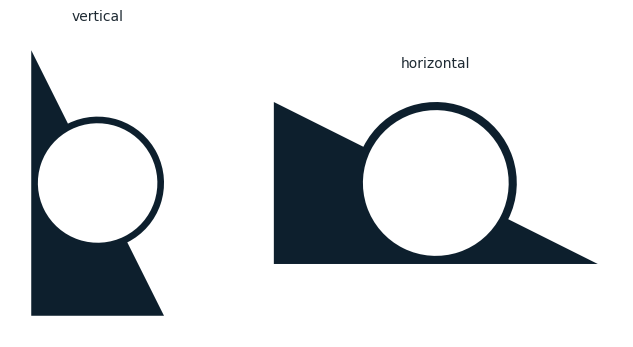

In [4]:
ORIENTATIONS = {
    "vertical": Affine2D(),
    "horizontal": Affine2D(np.array([[0, 1, 0], [1, 0, 0], [0, 0, 1]])),        # swap x and y
}

def oriented(name, path=None):
    return ORIENTATIONS[name].transform_path(primary_mark() if path is None else path)

fig, axes = plt.subplots(1, 2, figsize=(8, 4), gridspec_kw={"width_ratios": [1, 2]})
for ax, name in zip(axes, ORIENTATIONS):
    draw(ax, oriented(name))
    ax.set_title(name, fontsize=10, color=INK)
plt.show()

## The φ mark

A favicon is the small icon a browser shows next to the page title in a tab, and in bookmarks and history. Browsers draw it at 16 × 16 pixels. On high-resolution screens those 16 pixels are made of 32 physical ones, which is why `favicon.ico` carries both sizes. Sixteen pixels is therefore the smallest size the identity regularly appears at, and the size it has to survive.

At 16 pixels there is no room for a wedge, a void and a hairline ring. The φ mark keeps only the essentials: the circle and the line that runs through it. Take the triangle away from the construction and this is what remains. It happens to be the letter φ.

- **It uses the same circle.** The ring's outer diameter is 1.
- **The poles are the hypotenuse.** Each is exactly $1/\varphi$ long, the tips are $\sqrt{5}$ apart, and a pole plus the circle is $\varphi$.
- **The slash falls the same way as in the mark.** A "\\" slash reads as φ, the golden-ratio symbol. A "/" slash would read as ∅, the empty set.
- **It is drawn heavier** (`PHI_RING`), because it lives in browser tabs and sidebars and has to survive at 16 pixels.

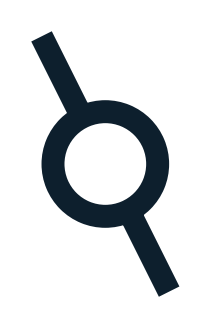

tips apart: 2.2361 (sqrt 5)   each pole beyond the circle: 0.6180 (1/phi)   pole + circle: 1.6180 (phi)


In [5]:
def phi_mark(ring=PHI_RING):
    """Ring of outer diameter 1 centered at the origin, with two poles along the hypotenuse direction."""
    reach = np.sqrt(5) / 2  # center to pole tip: each pole is 1/phi beyond the circle

    outer = arc(np.zeros(2), R, 0, 360)
    inner = arc(np.zeros(2), R - ring, 0, 360)[::-1]  # opposite direction, so it becomes a hole
    ring_path = Path([*outer, *inner],
                     [Path.MOVETO] + [Path.CURVE4] * (len(outer) - 1)
                     + [Path.MOVETO] + [Path.CURVE4] * (len(inner) - 1))

    poles = []
    for d in (U, -U):
        start, end = (R - ring / 2) * d, reach * d  # start inside the ring so the joint is seamless
        h = ring / 2 * N
        corners = np.array([start + h, start - h, end - h, end + h])
        x, y = corners.T
        if np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)) < 0:  # make it counterclockwise, like the ring's
            corners = corners[::-1]                                       # outer edge, so overlaps add up instead of cancelling
        poles.append(Path([*corners, corners[0]], [Path.MOVETO] + [Path.LINETO] * 3 + [Path.CLOSEPOLY]))

    return Path.make_compound_path(ring_path, *poles)


icon = phi_mark()
fig, ax = plt.subplots(figsize=(4, 4))
draw(ax, icon)
plt.show()

tip = np.sqrt(5) / 2
print(f"tips apart: {2 * tip:.4f} (sqrt 5)   each pole beyond the circle: {tip - R:.4f} (1/phi)   pole + circle: {tip + R:.4f} (phi)")

## Colour

One colour does the work: Midnight navy, the colour of the sites' navigation bars.

- **Navy on light backgrounds.** This is the default.
- **White when reversed** out of navy or any dark background.
- **Never link blue.** In this system blue means "you can click this", and the logo is not a link to anywhere.

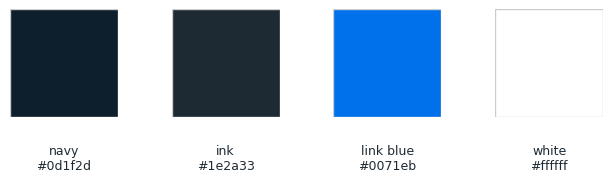

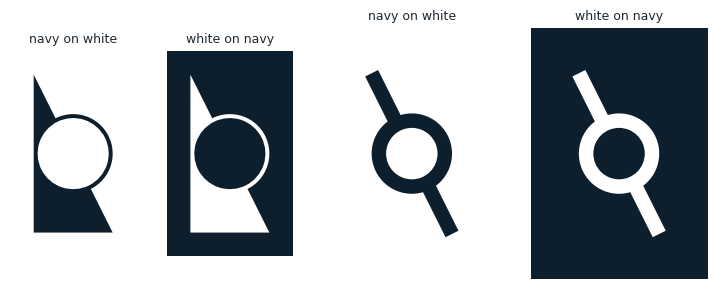

In [6]:
swatches = [("navy", NAVY), ("ink", INK), ("link blue", LINK_BLUE), ("white", WHITE)]
fig, axes = plt.subplots(1, len(swatches), figsize=(8, 1.4))
for ax, (name, hex_) in zip(axes, swatches):
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, color=hex_, ec="#cccccc"))
    ax.text(0.5, -0.25, f"{name}\n{hex_}", ha="center", va="top", fontsize=9, color=INK)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.axis("off")
plt.show()

colorways = [("navy on white", NAVY, WHITE), ("white on navy", WHITE, NAVY)]
fig, axes = plt.subplots(1, 4, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.4, 1.4]})
for i, (name, fg, bg) in enumerate(colorways):
    draw(axes[i], mark, color=fg, background=bg, pad=0.15)
    draw(axes[i + 2], icon, color=fg, background=bg, pad=0.25)
    axes[i].set_title(name, fontsize=9, color=INK)
    axes[i + 2].set_title(name, fontsize=9, color=INK)
plt.show()

## Stress test

A mark is only as good as its smallest appearance. Each tile below is rendered at the size shown and then enlarged, so every pixel is visible.

The primary mark needs room: its ring is `WIDTH`/2 of its height, so below about 64 pixels the ring falls under one and a half pixels and starts to dissolve. That is the φ mark's territory, and it stays crisp down to 16.

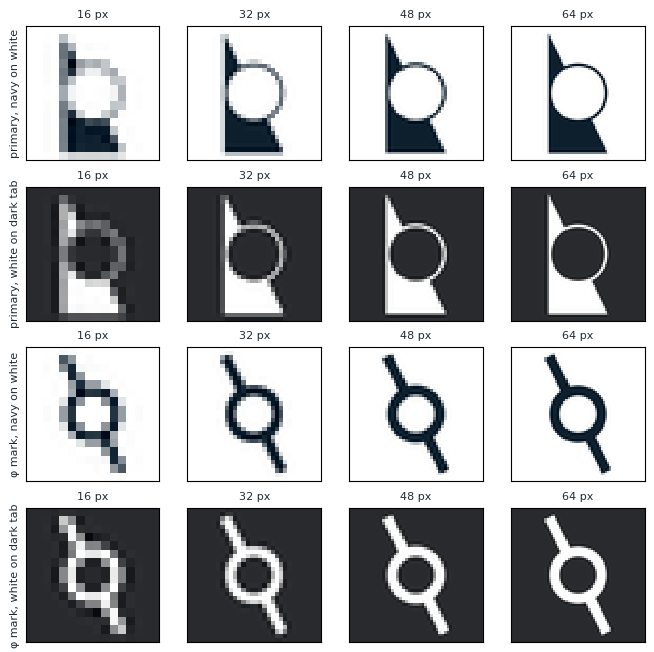

In [7]:
def raster(path, height_px, color=NAVY, background=None, square=False, pad=0.06, supersample=8):
    """Render a mark to a PIL image of the given pixel height, antialiased by supersampling."""
    box = path.get_extents()
    m = pad * max(box.width, box.height)
    x0, x1, y0, y1 = box.x0 - m, box.x1 + m, box.y0 - m, box.y1 + m
    if square:  # center the mark in a square canvas
        side = max(x1 - x0, y1 - y0)
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        x0, x1, y0, y1 = cx - side / 2, cx + side / 2, cy - side / 2, cy + side / 2
    width_px = height_px if square else max(1, round(height_px * (x1 - x0) / (y1 - y0)))
    big_w, big_h = width_px * supersample, height_px * supersample

    fig = plt.figure(figsize=(big_w / 100, big_h / 100), dpi=100)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.add_patch(PathPatch(path, facecolor=color, edgecolor="none"))
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.axis("off")
    fig.patch.set_alpha(0 if background is None else 1)
    fig.patch.set_facecolor(background or "none")
    fig.canvas.draw()
    image = Image.frombuffer("RGBA", fig.canvas.get_width_height(), fig.canvas.buffer_rgba()).copy()
    plt.close(fig)
    return image.resize((width_px, height_px), Image.LANCZOS)


rows = [("primary, navy on white", mark, NAVY, WHITE),
        ("primary, white on dark tab", mark, WHITE, DARK_TAB),
        ("φ mark, navy on white", icon, NAVY, WHITE),
        ("φ mark, white on dark tab", icon, WHITE, DARK_TAB)]
sizes = [16, 32, 48, 64]
fig, axes = plt.subplots(len(rows), len(sizes), figsize=(8, 8))
for (name, path, fg, bg), row in zip(rows, axes):
    for size, ax in zip(sizes, row):
        ax.imshow(raster(path, size, fg, bg, square=True), interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{size} px", fontsize=8, color=INK)
    row[0].set_ylabel(name, fontsize=8, color=INK)
plt.show()

## Rules of use

These are starting points, meant to be revised as the system gets used.

- **Pick the mark by size.** Use the primary mark from 64 pixels up: the home page, title slides, posters, social cards. Use the φ mark below that: favicons, the navbar, the sister sites' sidebars.
- **Pick the orientation by space.** Vertical by default. Horizontal only where the space is much wider than tall. Mirror the vertical mark only next to right-to-left text. Never rotate it to any other angle.
- **Leave it alone.** No stretching, outlines, shadows, gradients or effects. To change the weight, change `WIDTH` or `PHI_RING` here and export again. Never thin a mark by hand.
- **Give it air.** Keep empty space around the mark of at least half the circle's diameter (0.25 units).
- **Favicons look after themselves.** The SVG favicon turns white on its own when the browser is in dark mode.

## Export

This cell writes every version to the `logo/` folder next to this notebook. The SVGs are written straight from the geometry, so each holds one clean shape and nothing else.

| File | Use |
|---|---|
| `primary-<orientation>-navy.svg`, `-white.svg` | Vector mark, for each orientation and colourway |
| `primary-<orientation>-navy.png`, `-white.png` | The same, 512 pixels tall, transparent background |
| `phi-mark-navy.svg`, `-white.svg` | Vector φ mark |
| `favicon.svg` | Browser favicon, navy in light mode and white in dark mode |
| `favicon.ico` | Fallback favicon for older browsers, at 16, 32 and 48 pixels |
| `apple-touch-icon.png` | Phone home-screen icon, 180 pixels, white φ on navy |

In [8]:
def svg_d(path):
    """SVG path data for a matplotlib Path, with y flipped to point down."""
    parts = []
    for vertices, code in path.iter_segments(simplify=False, curves=True):
        pts = " ".join(f"{x:.4f} {-y:.4f}" for x, y in vertices.reshape(-1, 2))
        parts.append({Path.MOVETO: "M", Path.LINETO: "L", Path.CURVE3: "Q",
                      Path.CURVE4: "C", Path.CLOSEPOLY: "Z"}[code] + ("" if code == Path.CLOSEPOLY else " " + pts))
    return " ".join(parts)


def write_svg(path, filename, color=NAVY, dark_color=None, pad=0.0, square=False):
    box = path.get_extents()
    m = pad * max(box.width, box.height)
    x0, x1, y0, y1 = box.x0 - m, box.x1 + m, box.y0 - m, box.y1 + m
    if square:
        side = max(x1 - x0, y1 - y0)
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        x0, x1, y0, y1 = cx - side / 2, cx + side / 2, cy - side / 2, cy + side / 2
    style = ""
    if dark_color:
        style = (f"<style>path{{fill:{color}}}@media (prefers-color-scheme: dark)"
                 f"{{path{{fill:{dark_color}}}}}</style>")
    svg = (f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="{x0:.4f} {-y1:.4f} {x1 - x0:.4f} {y1 - y0:.4f}">'
           f'{style}<path fill="{color}" d="{svg_d(path)}"/></svg>\n')
    (OUT / filename).write_text(svg)


if EXPORT:
    OUT.mkdir(exist_ok=True)
    for name in ORIENTATIONS:
        for colour_name, colour in (("navy", NAVY), ("white", WHITE)):
            write_svg(oriented(name), f"primary-{name}-{colour_name}.svg", colour)
            raster(oriented(name), 512, colour, pad=0).save(OUT / f"primary-{name}-{colour_name}.png")
    for colour_name, colour in (("navy", NAVY), ("white", WHITE)):
        write_svg(icon, f"phi-mark-{colour_name}.svg", colour)

    write_svg(icon, "favicon.svg", NAVY, dark_color=WHITE, pad=0.04, square=True)
    # each size is rendered on its own, rather than shrunk from the largest
    raster(icon, 48, NAVY, square=True).save(OUT / "favicon.ico", sizes=[(16, 16), (32, 32), (48, 48)],
                                             append_images=[raster(icon, s, NAVY, square=True) for s in (16, 32)])

    touch = Image.new("RGBA", (180, 180), NAVY)
    glyph = raster(icon, 132, WHITE, square=True)
    touch.alpha_composite(glyph, ((180 - 132) // 2, (180 - 132) // 2))
    touch.convert("RGB").save(OUT / "apple-touch-icon.png")

    for f in sorted(OUT.iterdir()):
        print(f"{f.name:40s} {f.stat().st_size:>7,d} bytes")
else:
    print("EXPORT is False: nothing written")

apple-touch-icon.png                       4,117 bytes
favicon.ico                                2,941 bytes
favicon.svg                                1,879 bytes
phi-mark-navy.svg                          1,791 bytes
phi-mark-white.svg                         1,791 bytes
primary-horizontal-navy.png               30,530 bytes
primary-horizontal-navy.svg                  782 bytes
primary-horizontal-white.png              23,507 bytes
primary-horizontal-white.svg                 782 bytes
primary-vertical-navy.png                 15,230 bytes
primary-vertical-navy.svg                    782 bytes
primary-vertical-white.png                11,710 bytes
primary-vertical-white.svg                   782 bytes
